In [ ]:
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from typing import List, Optional, Dict, Tuple
import joblib
import os, re, ast, json, math, random, numpy as np, pandas as pd
import tensorflow as tf
import nibabel as nib
import seaborn as sns
from scipy.ndimage import zoom
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

In [ ]:
CT_DIR  = Path("/content/drive/MyDrive/Colab Notebooks/processed/ct_nifti")
MASK_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/mask_nifti")
RADIOMICS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_ct")

In [ ]:
MANIFEST_CSV = "/content/drive/MyDrive/Colab Notebooks/manifest.csv"
PATIENTS_CSV = "/content/drive/MyDrive/Colab Notebooks/PatientsData.csv"

RADIOMICS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_ct")

USE_CROPPED_CT = True
CT_NIFTI_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/ct_nifti")
CT_CROPPED_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/ct_cropped_nifti")

USE_CROPPED_NPY = False
NPY_CROPPED_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/npy_cropped")

TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
EPOCHS = 25
LR = 1e-4
VAL_SPLIT = 0.2
TEST_SPLIT = 0.1
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:

PATIENTS_CSV = "/content/drive/MyDrive/Colab Notebooks/PatientsData.csv"

df = pd.read_csv(PATIENTS_CSV, sep=";")
display(df.head(5))

def to_tokens(s):
    if pd.isna(s):
        return []
    s = str(s).upper().replace(" ", "")
    if s in ("", "NONE", "NAN"):
        return []
    return [t for t in s.split(",") if t]

def has_any(token_list, keys):
    return int(any(tok in token_list for tok in keys))

tokens_series = df["Biopsy positive"].apply(to_tokens)

codes = df["Code"].astype(str).str.extract(r"(\d+)")[0]

TTF1 = tokens_series.apply(lambda toks: has_any(toks, {"TTF1"}))
NAPSIN = tokens_series.apply(lambda toks: has_any(toks, {"NAPSIN", "NAPSINA", "NAPSINAM"}))

mask_missing = df["Biopsy positive"].isna() | (df["Biopsy positive"].astype(str).str.strip() == "")
TTF1 = TTF1.mask(mask_missing)
NAPSIN = NAPSIN.mask(mask_missing)


df_labels = pd.DataFrame({
    "Code": codes,
    "TTF1": TTF1.astype("Int64"),
    "NAPSIN": NAPSIN.astype("Int64")
})

display(df_labels.head(10))


print("Distribuție valori TTF1:", df_labels["TTF1"].value_counts(dropna=False).to_dict())
print("Distribuție valori NAPSIN:", df_labels["NAPSIN"].value_counts(dropna=False).to_dict())
print("Număr pacienți cu ambele etichete definite:",
      df_labels.dropna(subset=["TTF1", "NAPSIN"]).shape[0])

output_path = "/content/drive/MyDrive/Colab Notebooks/labels_TTF1_NAPSIN.csv"
df_labels.to_csv(output_path, index=False)
print(df_labels)


,Gender,Birthday,Age,Biopsy positive,CT,PET,Code
0,F,21.09.1948,77,"TTF1,NAPSIN A,RP",yes,yes,2011
1,M,26.02.1950,75,"CK AE1/AE3,CEA,CK7,TTF1,KI67",yes,yes,3111
2,M,12.11.1956,68,"TTF1,NAPSIN AM",yes,yes,4111
3,M,22.12.1961,63,"P63,CK HMW",yes,yes,5111
4,F,09.12.1946,78,P63,yes,yes,7011


,Code,TTF1,NAPSIN
0,2011,1,1
1,3111,1,0
2,4111,1,1
3,5111,0,0
4,7011,0,0
5,8011,1,1
6,9111,0,0
7,10111,1,1
8,11111,1,0
9,12111,1,0


Distribuție valori TTF1: {np.int64(1): 13, np.int64(0): 12}
Distribuție valori NAPSIN: {np.int64(0): 14, np.int64(1): 11}
Număr pacienți cu ambele etichete definite: 25
     Code  TTF1  NAPSIN
0    2011     1       1
1    3111     1       0
2    4111     1       1
3    5111     0       0
4    7011     0       0
5    8011     1       1
6    9111     0       0
7   10111     1       1
8   11111     1       0
9   12111     1       0
10  13111     0       0
11  15011     1       1
12  16111     0       0
13  22011     1       0
14  23111     1       1
15  24111     0       0
16  25111     0       0
17  26011     1       0
18  28111     1       1
19  29111     0       0
20  30011     1       0
21  40011     0       1
22  42111     0       1
23  43011     0       1
24  44111     0       1


In [ ]:
MANIFEST_CSV = "/content/drive/MyDrive/Colab Notebooks/processed/manifest_preproc.csv"
LABELS_CSV = "/content/drive/MyDrive/Colab Notebooks/labels_TTF1_NAPSIN.csv"
RADIOMICS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_ct")

PREFERRED_CT_SOURCE = "cropped_nifti"

def _norm_code(x: str) -> str:
    """Extrage doar cifrele din ID (ex: '2011 ' -> '2011')."""
    return pd.Series([x]).astype(str).str.extract(r"(\d+)")[0].iloc[0]

def _pick_ct_path(row, preferred=PREFERRED_CT_SOURCE):
    candidates_order = {
        "cropped_nifti": ["ct_cropped_nifti_path", "ct_nifti_path", "ct_cropped_npy_path", "ct_npy_path"],
        "cropped_npy": ["ct_cropped_npy_path", "ct_npy_path", "ct_cropped_nifti_path", "ct_nifti_path"],
        "nifti": ["ct_nifti_path", "ct_cropped_nifti_path", "ct_npy_path", "ct_cropped_npy_path"],
        "npy": ["ct_npy_path", "ct_cropped_npy_path", "ct_nifti_path", "ct_cropped_nifti_path"],
    }[preferred]

    chosen_col, chosen_path = None, None
    for col in candidates_order:
        if col in row and pd.notna(row[col]) and str(row[col]).strip():
            p = str(row[col]).strip()
            if os.path.exists(p):
                chosen_col, chosen_path = col, p
                break
    return chosen_col, chosen_path

def _build_radiomics_path(code: str) -> str:
    p = RADIOMICS_DIR / f"{code}_radiomics.txt"
    return str(p)

def _exists(p: str) -> bool:
    return (p is not None) and os.path.exists(p)


In [ ]:
def load_labels(labels_csv: str) -> pd.DataFrame:
    df = pd.read_csv(labels_csv, dtype=str)

    for col in ["TTF1", "NAPSIN"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df["Code"] = df["Code"].astype(str).apply(_norm_code)
    return df

def load_manifest(manifest_csv: str) -> pd.DataFrame:

    m = pd.read_csv(manifest_csv, dtype=str)
    m.columns = [c.strip() for c in m.columns]

    expected_cols = [
        "Code", "ct_nifti_path", "ct_npy_path",
        "ct_cropped_nifti_path", "ct_cropped_npy_path",
        "bbox_start_x", "bbox_start_y", "bbox_start_z",
        "bbox_size_x", "bbox_size_y", "bbox_size_z",
    ]

    if "Code" not in m.columns:
        alt = [c for c in m.columns if c.lower() == "code"]
        if alt:
            m.rename(columns={alt[0]: "Code"}, inplace=True)

    m["Code"] = m["Code"].astype(str).apply(_norm_code)
    return m

labels_df   = load_labels(LABELS_CSV)
manifest_df = load_manifest(MANIFEST_CSV)

print("Labels:", labels_df.shape, "| Manifest:", manifest_df.shape)

Labels: (25, 3) | Manifest: (25, 12)


In [ ]:
def build_data_index(labels: pd.DataFrame, manifest: pd.DataFrame, preferred=PREFERRED_CT_SOURCE) -> pd.DataFrame:

    use_labels = labels.dropna(subset=["TTF1", "NAPSIN"]).copy()
    idx = use_labels.merge(manifest, on="Code", how="left", suffixes=("",""))

    chosen_cols, chosen_paths = [], []
    for _, row in idx.iterrows():
        col, path = _pick_ct_path(row, preferred=preferred)
        chosen_cols.append(col)
        chosen_paths.append(path)

    idx["ct_source_col"] = chosen_cols
    idx["ct_path"] = chosen_paths

    idx["radiomics_path"] = idx["Code"].apply(_build_radiomics_path)

    idx["ct_exists"] = idx["ct_path"].apply(_exists)
    idx["radiomics_exists"] = idx["radiomics_path"].apply(_exists)

    bbox_cols = ["bbox_start_x","bbox_start_y","bbox_start_z","bbox_size_x","bbox_size_y","bbox_size_z"]
    for c in bbox_cols:
        if c in idx.columns:
            idx[c] = pd.to_numeric(idx[c], errors="coerce")

    idx_ok = idx[(idx["ct_exists"]) & (idx["radiomics_exists"])].copy()

    front_cols = ["Code","TTF1","NAPSIN","ct_path","ct_source_col","radiomics_path","ct_exists","radiomics_exists"]
    other_cols = [c for c in idx_ok.columns if c not in front_cols]
    idx_ok = idx_ok[front_cols + other_cols]

    return idx_ok

data_index = build_data_index(labels_df, manifest_df, preferred=PREFERRED_CT_SOURCE)


print(data_index["ct_source_col"].value_counts(dropna=False))

display(data_index.head(10))

INDEX_CSV = "/content/drive/MyDrive/Colab Notebooks/data_index_ct_radiomics.csv"
data_index.to_csv(INDEX_CSV, index=False)

ct_source_col
ct_cropped_nifti_path    25
Name: count, dtype: int64


,Code,TTF1,NAPSIN,ct_path,ct_source_col,radiomics_path,ct_exists,radiomics_exists,ct_nifti_path,ct_npy_path,mask_nifti_path,ct_cropped_nifti_path,ct_cropped_npy_path,bbox_start_x,bbox_start_y,bbox_start_z,bbox_size_x,bbox_size_y,bbox_size_z
0,2011,1,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,116,165,192,237,180,61
1,3111,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,199,220,318,282,211,65
2,4111,1,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,49,158,138,357,206,78
3,5111,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,123,111,131,251,199,59
4,7011,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,189,195,226,220,208,56
5,8011,1,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,235,272,299,251,169,66
6,9111,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,102,162,118,287,198,66
7,10111,1,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,118,159,115,287,174,78
8,11111,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,104,105,113,265,219,74
9,12111,1,0,/c

In [ ]:
TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
AUTOTUNE = tf.data.AUTOTUNE

def load_index(index_csv: str) -> pd.DataFrame:
    df = pd.read_csv(index_csv)
    df["Code"] = df["Code"].astype(str)
    return df

data_index = load_index(INDEX_CSV)
display(data_index.head(5))


def load_ct_volume(ct_path: str, target_shape=TARGET_SHAPE):
    img = nib.load(ct_path)
    vol = img.get_fdata().astype(np.float32)
    vol = np.nan_to_num(vol)

    p1, p99 = np.percentile(vol, [1, 99])
    if p99 > p1:
        vol = np.clip((vol - p1) / (p99 - p1), 0, 1)
    else:
        vol = (vol - vol.min()) / (vol.max() - vol.min() + 1e-6)

    factors = (
        target_shape[0] / vol.shape[0],
        target_shape[1] / vol.shape[1],
        target_shape[2] / vol.shape[2]
    )
    vol_resized = zoom(vol, factors, order=1)

    vol_resized = vol_resized[..., np.newaxis]
    return vol_resized



def load_radiomics_features(path: str):
    feats = {}
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or ":" not in line:
                continue
            k, v = line.split(":", 1)
            k = k.strip()
            v = v.strip()
            try:
                v_clean = v.replace("np.float64(", "").replace(")", "")
                val = float(v_clean)
                if k.startswith("original_"):
                    feats[k] = val
            except Exception:
                continue
    return feats

,Code,TTF1,NAPSIN,ct_path,ct_source_col,radiomics_path,ct_exists,radiomics_exists,ct_nifti_path,ct_npy_path,mask_nifti_path,ct_cropped_nifti_path,ct_cropped_npy_path,bbox_start_x,bbox_start_y,bbox_start_z,bbox_size_x,bbox_size_y,bbox_size_z
0,2011,1,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,116,165,192,237,180,61
1,3111,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,199,220,318,282,211,65
2,4111,1,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,49,158,138,357,206,78
3,5111,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,123,111,131,251,199,59
4,7011,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,189,195,226,220,208,56


In [ ]:
def build_radiomics_matrix(df: pd.DataFrame):
    rows = []
    for _, row in df.iterrows():
        feats = load_radiomics_features(row["radiomics_path"])
        feats["Code"] = row["Code"]
        rows.append(feats)
    r_df = pd.DataFrame(rows).fillna(0.0)
    return r_df


radiomics_df = build_radiomics_matrix(data_index)
display(radiomics_df.head(5))

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength,Code
0,0.779748,0.595795,152.529117,256.009192,276.193698,228.954491,233.925202,281.726390,2.565290e+06,199.622769,...,9.259974e-12,1.0,0.000003,2.062114e+09,0.0,1000000.0,0.0,0.0,0.0,2011
1,0.640068,0.586994,171.916764,292.876733,287.321700,244.669897,276.003623,287.742175,3.179862e+06,187.460922,...,5.712161e-12,1.0,0.000002,4.010056e+07,0.0,1000000.0,0.0,0.0,0.0,3111
2,0.755859,0.531013,171.416631,322.810411,382.922654,286.714140,338.614825,388.095296,5.550128e+06,243.999138,...,5.169797e-05,2.0,0.000003,3.970785e+11,0.0,1000000.0,0.0,0.0,0.0,4111
3,0.608012,0.579049,163.081669,281.637193,262.377589,212.432199,240.831892,274.271761,2.798182e+06,171.238885,...,7.404268e-12,1.0,0.000003,1.988523e+08,0.0,1000000.0,0.0,0.0,0.0,5111
4,0.732579,0.626003,154.582349,246.935586,233.918019,218.986848,228.790297,268.052307,2.421633e+06,180.899780,...,1.055364e-11,1.0,0.000003,2.352638e+09,0.0,1000000.0,0.0,0.0,0.0,7011


In [ ]:
merged = data_index.merge(radiomics_df, on="Code", how="left")
X_radio = merged[[c for c in merged.columns if c.startswith("original_")]].astype(np.float32).values

scaler = StandardScaler()
X_radio = scaler.fit_transform(X_radio).astype(np.float32)

y = merged[["TTF1", "NAPSIN"]].astype(np.float32).values
ct_paths = merged["ct_path"].tolist()
codes = merged["Code"].tolist()

print("Patients number:", len(codes))
print("Vectors dimensions:", X_radio.shape[1])

Patients number: 25
Vectors dimensions: 107


In [ ]:
def generator(ct_paths, X_radio, y):
    for i in range(len(ct_paths)):
        vol = load_ct_volume(ct_paths[i])
        radio = X_radio[i]
        label = y[i]
        yield (vol, radio), label

output_signature = (
    (tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
     tf.TensorSpec(shape=(X_radio.shape[1],), dtype=tf.float32)),
    tf.TensorSpec(shape=(2,), dtype=tf.float32)
)

dataset = tf.data.Dataset.from_generator(
    lambda: generator(ct_paths, X_radio, y),
    output_signature=output_signature
)

dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

for (vol, radio), label in dataset.take(1):
    print("Volum batch shape:", vol.shape)
    print("Radiomics batch shape:", radio.shape)
    print("Label batch shape:", label.shape)

Volum batch shape: (2, 128, 128, 128, 1)
Radiomics batch shape: (2, 107)
Label batch shape: (2, 2)


In [ ]:
TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
EPOCHS = 25
LR = 1e-4
VAL_SPLIT = 0.2
TEST_SPLIT = 0.1
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_ct_radiomics_1.keras"
SCALER_PATH = "/content/drive/MyDrive/Colab Notebooks/radiomics_scaler.pkl"

In [ ]:
if 'scaler' in globals():
    with open(SCALER_PATH, "wb") as f:
        pickle.dump(scaler, f)
    print("Radiomics scaler saved at:", SCALER_PATH)

Radiomics scaler saved at: /content/drive/MyDrive/Colab Notebooks/radiomics_scaler.pkl


In [ ]:
def get_subset_by_ids(df, ids, ct_paths, X_radio, y):
    """Return the subset of samples (paths, radiomics, labels) for the given patient IDs."""
    df_ids = df[df["Code"].isin(ids)]
    idxs = df.index[df["Code"].isin(ids)].tolist()
    subset_ct_paths = [ct_paths[i] for i in idxs]
    subset_X_radio = X_radio[idxs]
    subset_y = y[idxs]
    return subset_ct_paths, subset_X_radio, subset_y

In [ ]:
def sample_generator(ct_paths, X_radio, y):
    """Yield ((CT volume, radiomics vector), {'TTF1': ..., 'NAPSIN': ...})."""
    for i in range(len(ct_paths)):
        vol = load_ct_volume(ct_paths[i])  # (X,Y,Z,1)
        radio = X_radio[i].astype(np.float32)
        ttf1 = np.float32(y[i][0])
        naps = np.float32(y[i][1])
        yield (vol, radio), {"TTF1": ttf1, "NAPSIN": naps}

In [ ]:
def make_dataset(ct_paths, X_radio, y, batch_size, shuffle=False):
    """Build tf.data.Dataset for (CT, radiomics) -> {TTF1, NAPSIN}."""
    output_signature = (
        (
            tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
            tf.TensorSpec(shape=(X_radio.shape[1],), dtype=tf.float32),
        ),
        {
            "TTF1": tf.TensorSpec(shape=(), dtype=tf.float32),
            "NAPSIN": tf.TensorSpec(shape=(), dtype=tf.float32),
        }
    )

    ds = tf.data.Dataset.from_generator(
        lambda: sample_generator(ct_paths, X_radio, y),
        output_signature=output_signature
    )
    if shuffle:
        ds = ds.shuffle(buffer_size=min(256, len(ct_paths)))
    def expand_targets(inputs, targets):
        return inputs, {
            "TTF1": tf.expand_dims(targets["TTF1"], -1),
            "NAPSIN": tf.expand_dims(targets["NAPSIN"], -1)
        }
    ds = ds.map(expand_targets, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

In [ ]:
def prepare_datasets(train_ids, val_ids, test_ids):
    """Build train, validation and test datasets given patient ID lists."""
    ct_train, radio_train, y_train = get_subset_by_ids(data_index, train_ids, ct_paths, X_radio, y)
    ct_val, radio_val, y_val = get_subset_by_ids(data_index, val_ids, ct_paths, X_radio, y)
    ct_test, radio_test, y_test = get_subset_by_ids(data_index, test_ids, ct_paths, X_radio, y)

    train_ds = make_dataset(ct_train, radio_train, y_train, BATCH_SIZE, shuffle=True)
    val_ds = make_dataset(ct_val, radio_val, y_val, BATCH_SIZE, shuffle=False)
    test_ds = make_dataset(ct_test, radio_test, y_test, BATCH_SIZE, shuffle=False)
    return train_ds, val_ds, test_ds

In [ ]:
def conv3d_block(x, filters, k=3, s=1, p="same"):
    x = tf.keras.layers.Conv3D(filters, k, strides=s, padding=p)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    return x


def build_multimodal_twoheads(radio_dim, input_shape):
    """3D CNN + MLP with two independent heads (TTF1, NAPSIN)."""
    # CT branch
    in_ct = tf.keras.Input(shape=input_shape, name="ct")
    x = conv3d_block(in_ct, 16); x = conv3d_block(x, 16); x = tf.keras.layers.MaxPool3D(2)(x)
    x = conv3d_block(x, 32); x = conv3d_block(x, 32); x = tf.keras.layers.MaxPool3D(2)(x)
    x = conv3d_block(x, 64); x = conv3d_block(x, 64); x = tf.keras.layers.MaxPool3D(2)(x)
    x = conv3d_block(x, 128); x = tf.keras.layers.GlobalAveragePooling3D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)

    # Radiomics branch
    in_radio = tf.keras.Input(shape=(radio_dim,), name="radio")
    r = tf.keras.layers.Dense(256, activation="relu")(in_radio)
    r = tf.keras.layers.Dropout(0.3)(r)
    r = tf.keras.layers.Dense(128, activation="relu")(r)

    # Fusion
    z = tf.keras.layers.Concatenate()([x, r])
    z = tf.keras.layers.Dense(128, activation="relu")(z)
    z = tf.keras.layers.Dropout(0.3)(z)

    # Heads
    out_ttf1 = tf.keras.layers.Dense(1, activation="sigmoid", name="TTF1")(z)
    out_napsin = tf.keras.layers.Dense(1, activation="sigmoid", name="NAPSIN")(z)

    model = tf.keras.Model(inputs=[in_ct, in_radio],
                           outputs={"TTF1": out_ttf1, "NAPSIN": out_napsin})

    model.compile(
        optimizer=tf.keras.optimizers.Adam(LR),
        loss={"TTF1": "binary_crossentropy", "NAPSIN": "binary_crossentropy"},
        metrics={
            "TTF1": [tf.keras.metrics.AUC(name="AUC"), tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5)],
            "NAPSIN": [tf.keras.metrics.AUC(name="AUC"), tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5)],
        }
    )
    return model

In [ ]:
train_ids = ["2011", "10111", "23111", "22011", "26011", "42111", "43011", "24111", "25111", "29111"]
val_ids = ["30011", "40011", "28111", "4111", "5111", "11111", "16111"]
test_ids = ["31111", "44111", "15011", "8011", "13111", "12111", "9111", "7011"]

train_ds, val_ds, test_ds = prepare_datasets(train_ids, val_ids, test_ids)

# Build model
model = build_multimodal_twoheads(radio_dim=X_radio.shape[1], input_shape=TARGET_SHAPE+(1,))
model.summary()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]

# Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Evaluate
print("Evaluation on test set:")
test_metrics = model.evaluate(test_ds, return_dict=True)
print(test_metrics)

# Predictions
pred = model.predict(test_ds)
print("Sample predictions (first 5):")
print("TTF1:", pred["TTF1"][:5, 0])
print("NAPSIN:", pred["NAPSIN"][:5, 0])

print("Best model saved to:", MODEL_PATH)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct (InputLayer)     │ (None, 128, 128,  │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d (Conv3D)     │ (None, 128, 128,  │        448 │ ct[0][0]          │
│                     │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │         64 │ conv3d[0][0]      │
│ (BatchNormalizatio… │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_1 (Conv3D)   │ (None, 128, 128,  │      6,928 │ activation[0][0]  │
│                     │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         64 │ conv3d_1[0][0]    │
│ (BatchNormalizatio… │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d       │ (None, 64, 64,    │          0 │ activation_1[0][… │
│ (MaxPooling3D)      │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_2 (Conv3D)   │ (None, 64, 64,    │     13,856 │ max_pooling3d[0]… │
│                     │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv3d_2[0][0]    │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_3 (Conv3D)   │ (None, 64, 64,    │     27,680 │ activation_2[0][… │
│                     │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv3d_3[0][0]    │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_1     │ (None, 32, 32,    │          0 │ activation_3[0][… │
│ (MaxPooling3D)      │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_4 (Conv3D)   │ (None, 32, 32,    │     55,360 │ max_pooling3d_1[… │
│                     │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv3d_4[0][0]  

 Total params: 547,858 (2.09 MB)

 Trainable params: 547,154 (2.09 MB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/25
      5/Unknown 56s 334ms/step - NAPSIN_AUC: 0.4960 - NAPSIN_BinAcc: 0.6633 - NAPSIN_loss: 0.6417 - TTF1_AUC: 0.2858 - TTF1_BinAcc: 0.7333 - TTF1_loss: 0.5868 - loss: 1.2286

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


5/5 ━━━━━━━━━━━━━━━━━━━━ 73s 5s/step - NAPSIN_AUC: 0.4933 - NAPSIN_BinAcc: 0.6194 - NAPSIN_loss: 0.6633 - TTF1_AUC: 0.3148 - TTF1_BinAcc: 0.6944 - TTF1_loss: 0.6159 - loss: 1.2792 - val_NAPSIN_AUC: 0.8750 - val_NAPSIN_BinAcc: 0.4286 - val_NAPSIN_loss: 0.6753 - val_TTF1_AUC: 0.8333 - val_TTF1_BinAcc: 0.5714 - val_TTF1_loss: 0.6114 - val_loss: 1.2965 - learning_rate: 1.0000e-04
Epoch 2/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - NAPSIN_AUC: 0.6100 - NAPSIN_BinAcc: 0.6861 - NAPSIN_loss: 0.7717 - TTF1_AUC: 0.3006 - TTF1_BinAcc: 0.2931 - TTF1_loss: 0.7712 - loss: 1.5429 - val_NAPSIN_AUC: 0.9167 - val_NAPSIN_BinAcc: 0.4286 - val_NAPSIN_loss: 0.6704 - val_TTF1_AUC: 0.9167 - val_TTF1_BinAcc: 0.5714 - val_TTF1_loss: 0.6076 - val_loss: 1.2868 - learning_rate: 1.0000e-04
Epoch 3/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - NAPSIN_AUC: 0.9050 - NAPSIN_BinAcc: 0.7389 - NAPSIN_loss: 0.5869 - TTF1_AUC: 0.2366 - TTF1_BinAcc: 0.4667 - TTF1_loss: 0.9545 - loss: 1.5414 - val_NAPSIN_AUC: 0.9167 - val_NAPSIN_Bi

In [ ]:
LR = 1e-4
EPOCHS = 100
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_ct_radiomics_binary_1.keras"
THRESH = 0.4

def conv3d_block(x, filters, k=3, s=1, p="same"):
    x = tf.keras.layers.Conv3D(filters, k, strides=s, padding=p)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    return x

def build_model_twoheads(radio_dim, input_shape):
    # CT branch
    in_ct = tf.keras.Input(shape=input_shape, name="ct")
    x = conv3d_block(in_ct, 16); x = conv3d_block(x, 16); x = tf.keras.layers.MaxPool3D(2)(x)
    x = conv3d_block(x, 32); x = conv3d_block(x, 32); x = tf.keras.layers.MaxPool3D(2)(x)
    x = conv3d_block(x, 64); x = conv3d_block(x, 64); x = tf.keras.layers.MaxPool3D(2)(x)
    x = conv3d_block(x, 128); x = tf.keras.layers.GlobalAveragePooling3D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.30)(x)

    # Radiomics branch
    in_radio = tf.keras.Input(shape=(radio_dim,), name="radio")
    r = tf.keras.layers.Dense(256, activation="relu")(in_radio)
    r = tf.keras.layers.Dropout(0.30)(r)
    r = tf.keras.layers.Dense(128, activation="relu")(r)

    # Fusion
    z = tf.keras.layers.Concatenate()([x, r])
    z = tf.keras.layers.Dense(128, activation="relu")(z)
    z = tf.keras.layers.Dropout(0.30)(z)

    # Two heads (sigmoid during training; we will hard-threshold at test time)
    out_ttf1 = tf.keras.layers.Dense(1, activation="sigmoid", name="TTF1")(z)
    out_napsin = tf.keras.layers.Dense(1, activation="sigmoid", name="NAPSIN")(z)

    model = tf.keras.Model(inputs=[in_ct, in_radio], outputs={"TTF1": out_ttf1, "NAPSIN": out_napsin})
    model.compile(
        optimizer=tf.keras.optimizers.Adam(LR),
        loss={"TTF1": "binary_crossentropy", "NAPSIN": "binary_crossentropy"},
        metrics={
            "TTF1": [tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=THRESH)],
            "NAPSIN": [tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=THRESH)],
        }
    )
    return model

In [ ]:
train_ids = ["2011", "10111", "23111", "22011", "26011", "42111", "43011", "24111", "25111", "29111"]
val_ids = ["30011", "40011", "28111", "4111", "5111", "11111", "16111"]
test_ids = ["31111", "44111", "15011", "8011", "13111", "12111", "9111", "7011"]

train_ds, val_ds, test_ds = prepare_datasets(train_ids, val_ids, test_ids)


model = build_model_twoheads(radio_dim=X_radio.shape[1], input_shape=TARGET_SHAPE+(1,))
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)

y_true_ttf1, y_true_napsin = [], []
for (_, _), targets in test_ds.unbatch():
    y_true_ttf1.append(float(targets["TTF1"].numpy()))
    y_true_napsin.append(float(targets["NAPSIN"].numpy()))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_napsin = np.array(y_true_napsin, dtype=int)

pred = model.predict(test_ds)
y_pred_ttf1 = (pred["TTF1"].ravel()   >= THRESH).astype(int)
y_pred_napsin = (pred["NAPSIN"].ravel() >= THRESH).astype(int)

def print_binary_metrics(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)  # [[TN, FP], [FN, TP]]
    print(f"\n{name} — binary metrics (threshold={THRESH:.2f})")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("Confusion matrix [ [TN FP] [FN TP] ]:")
    print(cm)

print_binary_metrics(y_true_ttf1,   y_pred_ttf1,   "TTF1")
print_binary_metrics(y_true_napsin, y_pred_napsin, "NAPSIN")

Epoch 1/100
      5/Unknown 20s 338ms/step - NAPSIN_BinAcc: 0.5000 - NAPSIN_loss: 0.7099 - TTF1_BinAcc: 0.4450 - TTF1_loss: 0.7271 - loss: 1.4370

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


5/5 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - NAPSIN_BinAcc: 0.5000 - NAPSIN_loss: 0.7103 - TTF1_BinAcc: 0.4708 - TTF1_loss: 0.7195 - loss: 1.4298 - val_NAPSIN_BinAcc: 0.5714 - val_NAPSIN_loss: 0.7069 - val_TTF1_BinAcc: 0.5714 - val_TTF1_loss: 0.7014 - val_loss: 1.4010 - learning_rate: 1.0000e-04
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - NAPSIN_BinAcc: 0.5833 - NAPSIN_loss: 0.7164 - TTF1_BinAcc: 0.5694 - TTF1_loss: 0.7541 - loss: 1.4705 - val_NAPSIN_BinAcc: 0.5714 - val_NAPSIN_loss: 0.7035 - val_TTF1_BinAcc: 0.5714 - val_TTF1_loss: 0.7013 - val_loss: 1.3993 - learning_rate: 1.0000e-04
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - NAPSIN_BinAcc: 0.6528 - NAPSIN_loss: 0.7125 - TTF1_BinAcc: 0.6236 - TTF1_loss: 0.8358 - loss: 1.5483 - val_NAPSIN_BinAcc: 0.4286 - val_NAPSIN_loss: 0.7001 - val_TTF1_BinAcc: 0.5714 - val_TTF1_loss: 0.7005 - val_loss: 1.3983 - learning_rate: 1.0000e-04
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - NAPSIN_BinAcc: 0.4167 - NAPSIN_loss: 0.8469 - TTF1_Bin

/tmp/ipython-input-2364732424.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ttf1.append(float(targets["TTF1"].numpy()))
/tmp/ipython-input-2364732424.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_napsin.append(float(targets["NAPSIN"].numpy()))


4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 748ms/step

TTF1 — binary metrics (threshold=0.40)
Accuracy:  0.5714
Precision: 0.5000
Recall:    0.6667
F1-score:  0.5714
Confusion matrix [ [TN FP] [FN TP] ]:
[[2 2]
 [1 2]]

NAPSIN — binary metrics (threshold=0.40)
Accuracy:  0.7143
Precision: 1.0000
Recall:    0.3333
F1-score:  0.5000
Confusion matrix [ [TN FP] [FN TP] ]:
[[4 0]
 [2 1]]


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


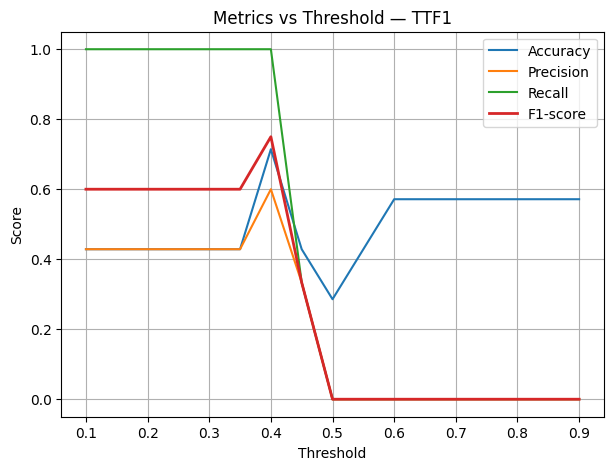

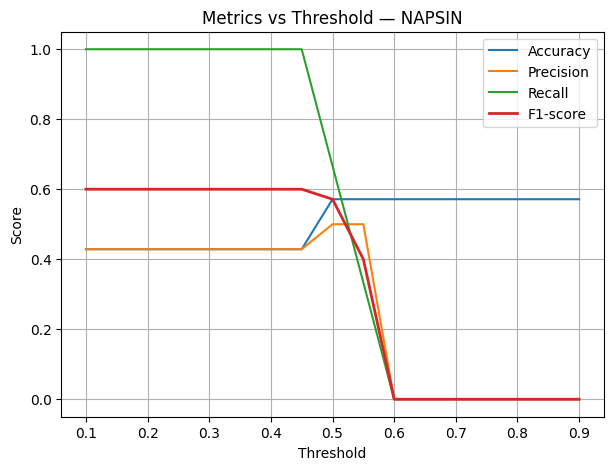

In [ ]:
try:
    _ = model.inputs
except NameError:
    MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_ct_radiomics_1.keras"
    model = tf.keras.models.load_model(MODEL_PATH)
    print("Loaded model from:", MODEL_PATH)

y_true_ttf1, y_true_napsin = [], []
for _, targets in test_ds.unbatch().map(lambda x, t: (0, t)):
    y_true_ttf1.append(float(targets["TTF1"].numpy()[0]))
    y_true_napsin.append(float(targets["NAPSIN"].numpy()[0]))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_napsin = np.array(y_true_napsin, dtype=int)

pred = model.predict(test_ds, verbose=0)
p_test_ttf1 = pred["TTF1"].ravel()
p_test_napsin = pred["NAPSIN"].ravel()

def plot_threshold_metrics(y_true, y_prob, name):
    thresholds = np.arange(0.10, 0.91, 0.05)
    acc, prec, rec, f1 = [], [], [], []
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        acc.append(accuracy_score(y_true, y_pred))
        prec.append(precision_score(y_true, y_pred, zero_division=0))
        rec.append(recall_score(y_true, y_pred, zero_division=0))
        f1.append(f1_score(y_true, y_pred, zero_division=0))

    plt.figure(figsize=(7,5))
    plt.plot(thresholds, acc,  label="Accuracy")
    plt.plot(thresholds, prec, label="Precision")
    plt.plot(thresholds, rec,  label="Recall")
    plt.plot(thresholds, f1,   label="F1-score", linewidth=2)
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Metrics vs Threshold — {name}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_threshold_metrics(y_true_ttf1,   p_test_ttf1,   "TTF1")
plot_threshold_metrics(y_true_napsin, p_test_napsin, "NAPSIN")


Epoch 1/30
      5/Unknown 26s 341ms/step - NAPSIN_BinAcc: 0.7417 - NAPSIN_loss: 0.7196 - TTF1_BinAcc: 0.4750 - TTF1_loss: 0.6630 - loss: 1.3826

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


5/5 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - NAPSIN_BinAcc: 0.7014 - NAPSIN_loss: 0.7305 - TTF1_BinAcc: 0.4792 - TTF1_loss: 0.6746 - loss: 1.4051 - val_NAPSIN_BinAcc: 0.4286 - val_NAPSIN_loss: 0.6679 - val_TTF1_BinAcc: 0.5714 - val_TTF1_loss: 0.7550 - val_loss: 1.4197 - learning_rate: 1.0000e-04
Epoch 2/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - NAPSIN_BinAcc: 0.4583 - NAPSIN_loss: 0.8106 - TTF1_BinAcc: 0.4500 - TTF1_loss: 0.6656 - loss: 1.4762 - val_NAPSIN_BinAcc: 0.4286 - val_NAPSIN_loss: 0.6671 - val_TTF1_BinAcc: 0.5714 - val_TTF1_loss: 0.7516 - val_loss: 1.4169 - learning_rate: 1.0000e-04
Epoch 3/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - NAPSIN_BinAcc: 0.4306 - NAPSIN_loss: 0.7666 - TTF1_BinAcc: 0.5486 - TTF1_loss: 0.7352 - loss: 1.5018 - val_NAPSIN_BinAcc: 0.4286 - val_NAPSIN_loss: 0.6674 - val_TTF1_BinAcc: 0.5714 - val_TTF1_loss: 0.7495 - val_loss: 1.4159 - learning_rate: 1.0000e-04
Epoch 4/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - NAPSIN_BinAcc: 0.4500 - NAPSIN_loss: 0.6488 - TTF1_BinAcc:

/tmp/ipython-input-3514106214.py:20: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ttf1.append(float(targets["TTF1"].numpy()))
/tmp/ipython-input-3514106214.py:21: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_napsin.append(float(targets["NAPSIN"].numpy()))


4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 600ms/step

TTF1 — binary metrics (threshold=0.40)
Accuracy:  0.5714
Precision: 0.5000
Recall:    0.6667
F1-score:  0.5714
Confusion matrix [[TN FP] [FN TP]]:
[[2 2]
 [1 2]]


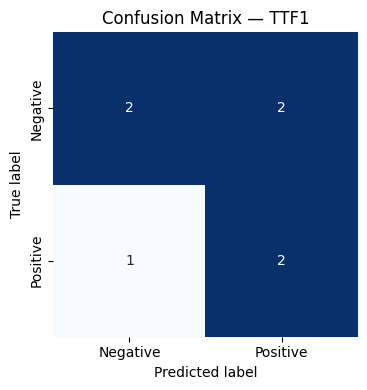


NAPSIN — binary metrics (threshold=0.40)
Accuracy:  0.4286
Precision: 0.4286
Recall:    1.0000
F1-score:  0.6000
Confusion matrix [[TN FP] [FN TP]]:
[[0 4]
 [0 3]]


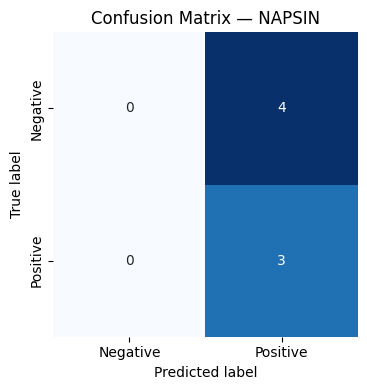

In [ ]:
EPOCHS = 30

train_ids = ["2011", "10111", "23111", "22011", "26011", "42111", "43011", "24111", "25111", "29111"]
val_ids = ["30011", "40011", "28111", "4111", "5111", "11111", "16111"]
test_ids = ["31111", "44111", "15011", "8011", "13111", "12111", "9111", "7011"]

train_ds, val_ds, test_ds = prepare_datasets(train_ids, val_ids, test_ids)


model = build_model_twoheads(radio_dim=X_radio.shape[1], input_shape=TARGET_SHAPE+(1,))
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)

y_true_ttf1, y_true_napsin = [], []
for (_, _), targets in test_ds.unbatch():
    y_true_ttf1.append(float(targets["TTF1"].numpy()))
    y_true_napsin.append(float(targets["NAPSIN"].numpy()))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_napsin = np.array(y_true_napsin, dtype=int)

pred = model.predict(test_ds)
y_pred_ttf1 = (pred["TTF1"].ravel()   >= THRESH).astype(int)
y_pred_napsin = (pred["NAPSIN"].ravel() >= THRESH).astype(int)

def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, square=True)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

def print_binary_metrics(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)

    print(f"\n{name} — binary metrics (threshold={THRESH:.2f})")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(cm)

    plot_confusion_matrix(y_true, y_pred, name)

print_binary_metrics(y_true_ttf1,   y_pred_ttf1,   "TTF1")
print_binary_metrics(y_true_napsin, y_pred_napsin, "NAPSIN")